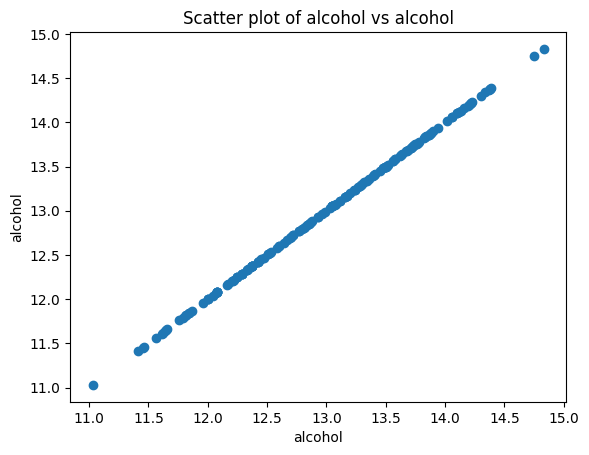

In [ ]:
# Question 1
from sklearn.datasets import load_wine
import pandas as pd

# Load the wine dataset
data = load_wine()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = pd.Series(data.target)

# Display the first few rows of the dataset
df.head()
# Compute the frequency of each value of the categorical feature ('target')
categorical_feature = 'target'
frequency = df[categorical_feature].value_counts()
frequency
# Univariate summary (mean and standard deviation)
univariate_summary = df.describe().loc[['mean', 'std']]
univariate_summary
# Multivariate summary: correlation matrix
correlation_matrix = df.corr()
correlation_matrix
# Group by the categorical feature ('target') and compute the median for each numerical feature
grouped_median = df.groupby('target').median()
grouped_median
import matplotlib.pyplot as plt

# Find the pair of numerical features with the highest correlation
correlation_matrix = df.corr()
highly_corr_pair = correlation_matrix.unstack().idxmax()

# Create the scatter plot for the most highly correlated features
feature1, feature2 = highly_corr_pair
plt.scatter(df[feature1], df[feature2])
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title(f"Scatter plot of {feature1} vs {feature2}")
plt.show()


In [ ]:
#Question 3
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

# Load the dataset
country_df = pd.read_csv('/country-income.csv')

# Step 1: Inspect column names
print("Columns:", country_df.columns)
print(country_df.head())

# Step 2: Separate numeric and categorical columns
numeric_cols = country_df.select_dtypes(include=['float64', 'int64']).columns
categorical_cols = country_df.select_dtypes(include=['object']).columns

# Step 3: Impute missing values in numeric columns using mean
imputer = SimpleImputer(strategy='mean')
country_df[numeric_cols] = imputer.fit_transform(country_df[numeric_cols])

# Step 4: Encode categorical columns using LabelEncoder
label_encoder = LabelEncoder()
for col in categorical_cols:
    country_df[col] = label_encoder.fit_transform(country_df[col].astype(str))

# Step 5: Display cleaned dataset
print("Cleaned dataset:")
print(country_df.head())

# Step 6: Income analysis
# Total income
print("Total income:", country_df['Income'].sum())

# Income by Region
region_results = country_df.groupby('Region')['Income'].agg(['sum', 'mean', 'min', 'max'])
print("\nIncome by Region:")
print(region_results)

# Income by Online Shopper status
shopper_results = country_df.groupby('Online Shopper')['Income'].agg(['sum', 'mean', 'min', 'max'])
print("\nIncome by Online Shopper:")
print(shopper_results)

# Income for Age between 40 and 50
age_filtered = country_df[(country_df['Age'] >= 40) & (country_df['Age'] <= 50)]
age_results = age_filtered['Income'].agg(['sum', 'mean', 'min', 'max'])
print("\nIncome for Age 40–50:")
print(age_results)


Columns: Index(['Region', 'Age', 'Income', 'Online Shopper'], dtype='object')
   Region   Age   Income Online Shopper
0   India  49.0  86400.0             No
1  Brazil  32.0  57600.0            Yes
2     USA  35.0  64800.0             No
3  Brazil  43.0  73200.0             No
4     USA  45.0      NaN            Yes
Cleaned dataset:
   Region   Age        Income  Online Shopper
0       1  49.0  86400.000000               0
1       0  32.0  57600.000000               1
2       2  35.0  64800.000000               0
3       0  43.0  73200.000000               0
4       2  45.0  76533.333333               1
Total income: 765333.3333333333

Income by Region:
                  sum          mean      min      max
Region                                               
0       193200.000000  64400.000000  57600.0  73200.0
1       331200.000000  82800.000000  69600.0  94800.0
2       240933.333333  80311.111111  64800.0  99600.0

Income by Online Shopper:
                          sum          me

Index(['Index', 'Gender', 'Size', 'Height'], dtype='object')
   Index Gender  Size  Height
0      1      F   5.5    60.0
1      2      F   6.0    60.0
2      3      F   7.0    60.0
3      4      F   8.0    60.0
4      5      F   8.0    60.0


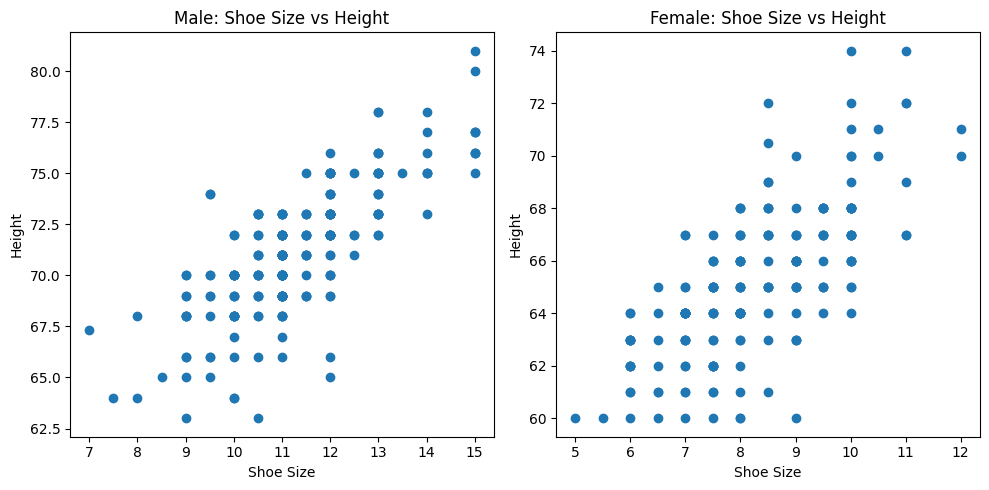

(np.float64(0.7677093547300977), np.float64(0.7078119417143971))

In [ ]:
#Question 4
import pandas as pd

# Load the dataset
shoesize_df = pd.read_csv('/shoesize.csv')

# Check the actual columns
print(shoesize_df.columns)
print(shoesize_df.head())


# Display the first few rows of the dataset
shoesize_df.head()
import matplotlib.pyplot as plt

# Separate the data by gender
male_data = shoesize_df[shoesize_df['Gender'] == 'M']
female_data = shoesize_df[shoesize_df['Gender'] == 'F']

# Plot for male subjects
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.scatter(male_data['Size'], male_data['Height'])
plt.title("Male: Shoe Size vs Height")
plt.xlabel('Shoe Size')
plt.ylabel('Height')

# Plot for female subjects
plt.subplot(1, 2, 2)
plt.scatter(female_data['Size'], female_data['Height'])
plt.title("Female: Shoe Size vs Height")
plt.xlabel('Shoe Size')
plt.ylabel('Height')

plt.tight_layout()
plt.show()
from scipy.stats import pearsonr

# Compute Pearson's correlation for male subjects
male_corr, _ = pearsonr(male_data['Size'], male_data['Height'])

# Compute Pearson's correlation for female subjects
female_corr, _ = pearsonr(female_data['Size'], female_data['Height'])

male_corr, female_corr


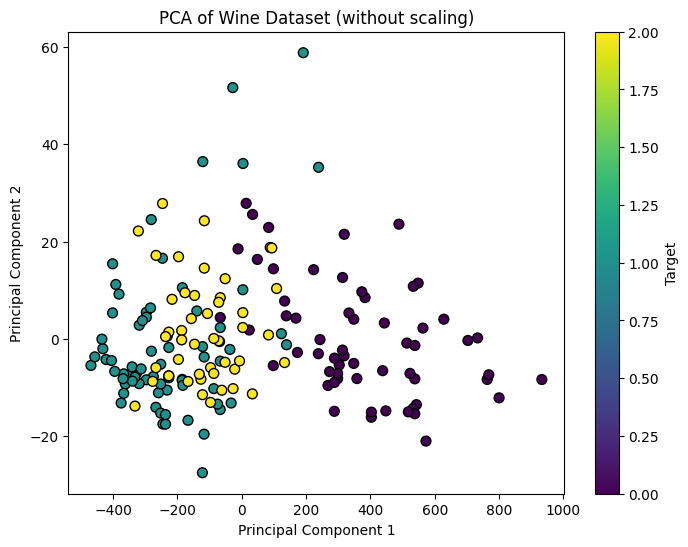

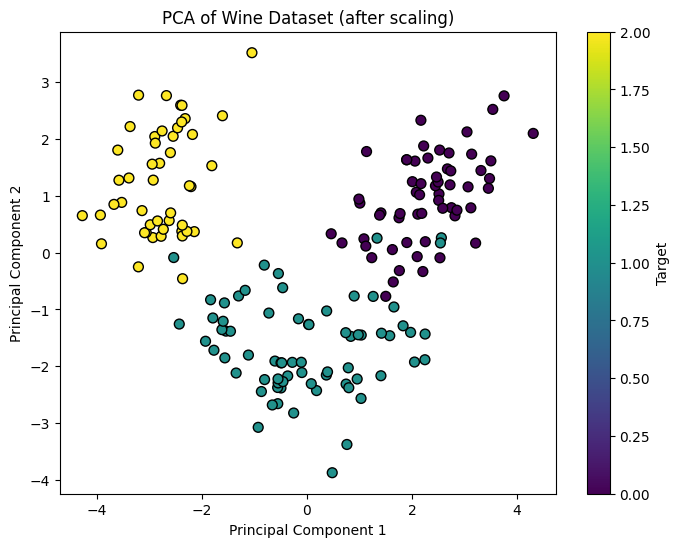

In [ ]:
# Question 5
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Extract features and target
X = df.drop(columns=['target'])
y = df['target']

# Apply PCA without scaling the data
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Plot the scatterplot color-coded by the 'target' column
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', edgecolor='k', s=50)
plt.title("PCA of Wine Dataset (without scaling)")
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Target')
plt.show()
# Standardize the data before applying PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA again with standardized data
pca = PCA(n_components=2)
X_pca_scaled = pca.fit_transform(X_scaled)

# Plot the scatterplot color-coded by the 'target' column
plt.figure(figsize=(8, 6))
plt.scatter(X_pca_scaled[:, 0], X_pca_scaled[:, 1], c=y, cmap='viridis', edgecolor='k', s=50)
plt.title("PCA of Wine Dataset (after scaling)")
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Target')
plt.show()


In [ ]:
import pandas as pd
from cubes import Workspace

# Load the dataset
country_df = pd.read_csv('country-income.csv')

# Initialize the workspace
workspace = Workspace()

# Create a JSON schema for the data cube model
model = {
    "dimensions": [
        {"name": "region", "levels": [{"name": "region"}]},
        {"name": "age", "levels": [{"name": "age"}]},
        {"name": "online_shopper", "levels": [{"name": "online_shopper"}]}
    ],
    "measures": [
        {"name": "income", "aggregates": ["sum", "avg", "min", "max"]}
    ]
}

# Define the cube and load data
workspace.register_schema(model)
# Save the schema as a JSON file
with open('data_cube_model.json', 'w') as f:
    f.write(str(model))
cube = workspace.cube("country_income")
total_income = cube.aggregate(measures=["income"])
print(total_income)
region_results = cube.aggregate(drilldown=["region"], measures=["income"])
print(region_results)
online_shopper_results = cube.aggregate(drilldown=["online_shopper"], measures=["income"])
print(online_shopper_results)
age_40_50_results = cube.aggregate(drilldown=["age"], filters={"age": {"$gte": 40, "$lte": 50}}, measures=["income"])
print(age_40_50_results)


ModuleNotFoundError: No module named 'cubes'